# Ecobici — EDA

Análisis exploratorio sobre los datos limpios de `data_cleaning.ipynb`.

## 0. Configuración

Carga los viajes limpios de septiembre 2026 (todas las estaciones; la subred se filtra con máscaras) y los docks de cada estación según el feed. Los días hábiles se calculan a partir de `es_habil`: lunes a viernes, sin el festivo del 16 ni el 14 y 15 de septiembre (cierre en Buenavista).

In [22]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

RUTA_VIAJES = Path("data/clean/trips_2026-09.parquet")
RUTA_ESTACIONES = Path("data/raw/station_information.json")
DIR_FIG = Path("outputs/figuras")
DIR_TAB = Path("outputs/tablas")
DIR_FIG.mkdir(parents=True, exist_ok=True)
DIR_TAB.mkdir(parents=True, exist_ok=True)

SUBRED = {"271-272": "Buenavista", "273-274": "Buenavista",
          "014": "Reforma", "027": "Reforma", "018": "Reforma"}
ESTACIONES = list(SUBRED)                 # orden fijo: Buenavista y luego Reforma
COLORES = {"Buenavista": "#d1495b", "Reforma": "#2e86ab"}
HORAS = list(range(5, 24))                # horario de servicio: 05:00 a 23:59
COL_RET, COL_ARR = "Ciclo_Estacion_Retiro", "Ciclo_EstacionArribo"

df = pd.read_parquet(RUTA_VIAJES)
info = pd.DataFrame(json.loads(RUTA_ESTACIONES.read_text())["data"]["stations"]).set_index("short_name")
DOCKS = info["capacity"].reindex(ESTACIONES)

DIAS = pd.DatetimeIndex(sorted(df.loc[df.es_habil, "fecha"].unique()))
N_DIAS = len(DIAS)

print(f"Viajes en el archivo: {len(df):,}")
print(f"Días hábiles: {N_DIAS} (del {DIAS.min():%d/%m} al {DIAS.max():%d/%m})")
pd.DataFrame({"grupo": pd.Series(SUBRED), "docks": DOCKS})

Viajes en el archivo: 1,495,520
Días hábiles: 19 (del 01/09 al 30/09)


,grupo,docks
271-272,Buenavista,74
273-274,Buenavista,70
014,Reforma,39
027,Reforma,43
018,Reforma,39


## 1. Estadísticas descriptivas por estación y hora

Contamos retiros y devoluciones de cada estación por día hábil y hora, de 5 a 23 h.

- **Retiros:** día y hora del retiro.
- **Devoluciones:** día y hora del arribo, que es cuando la bici entra a la estación. Que el día sea hábil se revisa con la fecha de arribo.
- **Rejilla completa:** las combinaciones estación × día × hora sin viajes cuentan como 0. Sin esos ceros las medias salen infladas.

Salen dos tablas: el detalle por estación y hora (media ± desviación estándar entre días; la variable `descriptivas` también guarda el mínimo y el máximo) y un resumen por estación.

El **flujo neto** es devoluciones − retiros: si es positivo la estación gana bicis (se llena); si es negativo, las pierde (se vacía).

La gráfica muestra arriba retiros y devoluciones por hora (el punto marca la hora pico) y abajo el flujo neto de cada hora. Las estaciones comparten escala para que se puedan comparar.

Retiros por hora (media ± desviación estándar entre los 19 días hábiles)


estacion,271-272,273-274,014,027,018
hora,,,,,
5,17.9 ± 5.0,0.8 ± 1.0,0.6 ± 0.6,0.3 ± 0.6,1.6 ± 1.2
6,45.7 ± 11.1,3.1 ± 2.2,2.3 ± 1.5,2.7 ± 1.3,3.7 ± 1.4
7,60.0 ± 25.0,39.6 ± 26.6,9.1 ± 4.0,9.2 ± 2.8,8.5 ± 3.3
8,110.7 ± 41.6,24.6 ± 24.3,11.0 ± 4.1,13.8 ± 5.3,17.4 ± 5.4
9,61.9 ± 30.7,15.9 ± 18.0,9.7 ± 2.9,13.4 ± 5.6,12.9 ± 4.5
10,28.3 ± 17.2,9.1 ± 9.4,6.5 ± 2.5,8.0 ± 3.3,7.8 ± 2.7
11,13.0 ± 8.4,7.5 ± 6.4,8.1 ± 3.3,10.7 ± 4.3,7.6 ± 2.5
12,11.0 ± 5.4,5.5 ± 4.2,10.6 ± 4.6,14.3 ± 4.0,10.5 ± 3.5
13,14.6 ± 5.5,5.3 ± 3.6,16.0 ± 4.0,19.0 ± 4.0,14.8 ± 3.9


Devoluciones por hora (media ± desviación estándar entre los 19 días hábiles)


estacion,271-272,273-274,014,027,018
hora,,,,,
5,3.5 ± 1.7,0.3 ± 0.4,2.8 ± 1.7,3.0 ± 1.2,6.7 ± 2.1
6,6.1 ± 1.9,0.9 ± 0.9,9.0 ± 2.2,10.0 ± 3.1,11.8 ± 2.3
7,5.0 ± 2.3,2.0 ± 1.5,32.4 ± 9.9,19.5 ± 5.0,36.0 ± 7.8
8,5.4 ± 2.2,3.4 ± 2.2,51.5 ± 13.7,36.3 ± 6.5,38.6 ± 6.6
9,4.1 ± 2.3,2.3 ± 1.4,37.0 ± 25.7,29.7 ± 5.9,22.7 ± 9.1
10,5.7 ± 2.6,1.9 ± 1.4,19.0 ± 6.5,14.9 ± 4.7,14.5 ± 5.4
11,7.7 ± 4.1,2.8 ± 1.5,12.7 ± 4.7,12.6 ± 3.8,12.4 ± 4.1
12,6.6 ± 2.9,3.1 ± 2.0,11.0 ± 4.0,13.3 ± 3.7,10.4 ± 3.5
13,13.6 ± 5.4,4.6 ± 2.3,12.9 ± 4.6,14.8 ± 3.6,13.7 ± 3.3


,grupo,docks,retiros_dia,devoluciones_dia,flujo_neto_dia,retiros_por_dock,devoluciones_por_dock,hora_pico_retiro,hora_pico_devolucion
271-272,Buenavista,74,491.2,678.1,186.9,6.6,9.2,8,17
273-274,Buenavista,70,150.2,221.1,70.8,2.1,3.2,7,18
014,Reforma,39,218.6,272.7,54.2,5.6,7.0,17,8
027,Reforma,43,268.2,287.8,19.6,6.2,6.7,17,8
018,Reforma,39,219.4,250.0,30.6,5.6,6.4,15,8


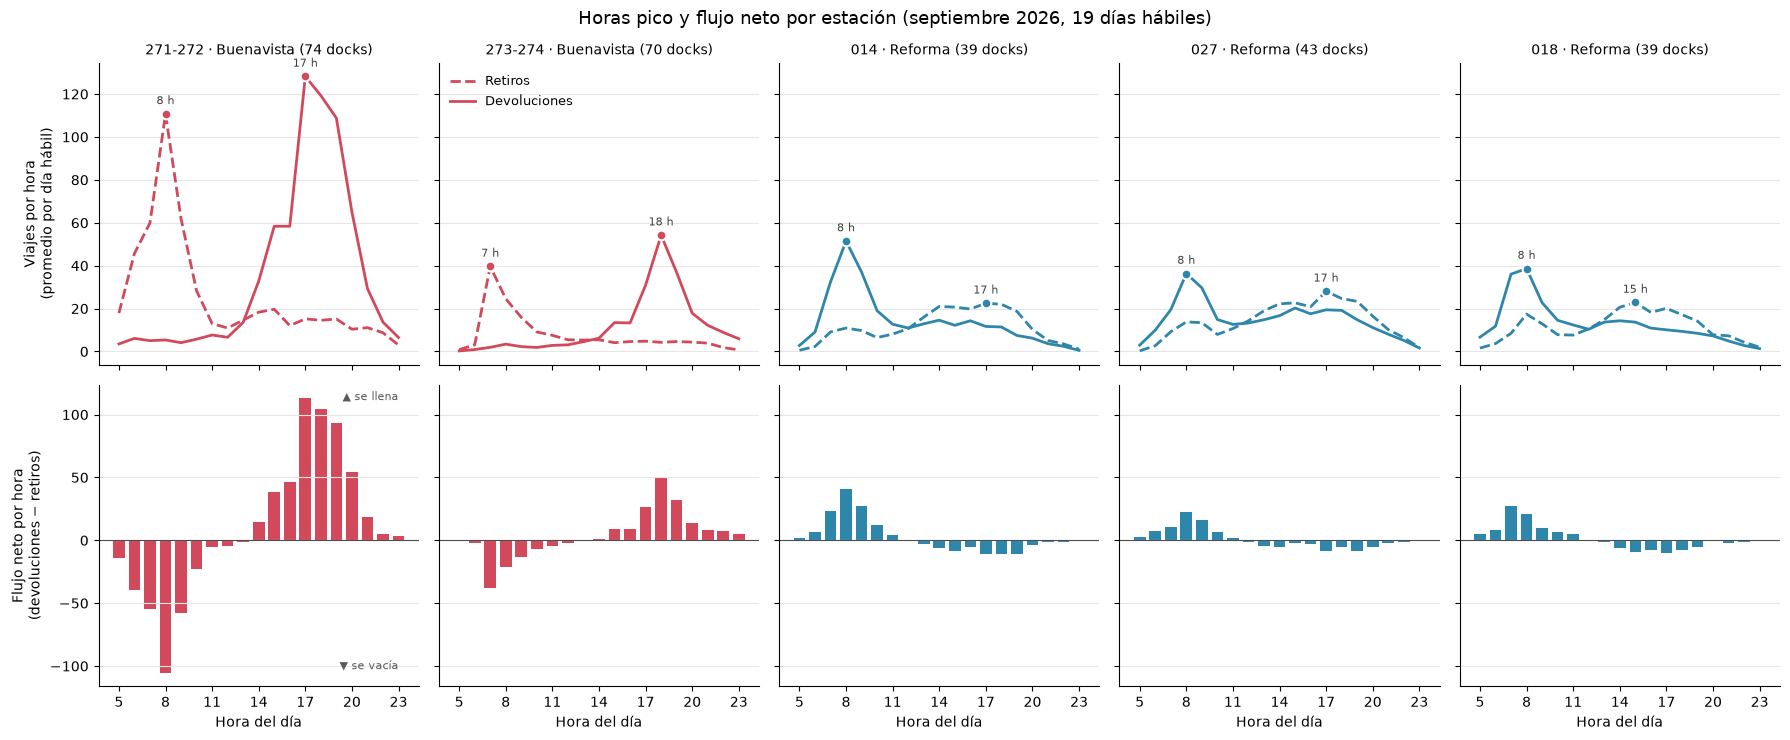

In [23]:
# Retiros: día y hora del retiro
m_ret = df.es_habil & df.en_horario & df.retiro_subred
ret = pd.DataFrame({"estacion": df.loc[m_ret, COL_RET].astype(str),
                    "fecha": df.loc[m_ret, "fecha"],
                    "hora": df.loc[m_ret, "hora_retiro"].astype(int)})

# Devoluciones: día y hora del arribo (lo que entra a la estación en esa hora)
fecha_arribo = df["arribo"].dt.normalize()
m_dev = df.arribo_subred & fecha_arribo.isin(DIAS) & df.hora_arribo.between(5, 23)
dev = pd.DataFrame({"estacion": df.loc[m_dev, COL_ARR].astype(str),
                    "fecha": fecha_arribo[m_dev],
                    "hora": df.loc[m_dev, "hora_arribo"].astype(int)})

# Rejilla completa estación × día × hora: las combinaciones sin viajes cuentan como 0
rejilla = pd.MultiIndex.from_product([ESTACIONES, DIAS, HORAS], names=["estacion", "fecha", "hora"])
conteos = pd.DataFrame({
    "retiros": ret.groupby(["estacion", "fecha", "hora"]).size().reindex(rejilla, fill_value=0),
    "devoluciones": dev.groupby(["estacion", "fecha", "hora"]).size().reindex(rejilla, fill_value=0),
})

# Tabla larga: media, desviación estándar, mínimo y máximo entre días, por estación y hora
descriptivas = conteos.groupby(["estacion", "hora"], sort=False).agg(["mean", "std", "min", "max"]).round(2)
descriptivas.columns = [f"{var}_{est}" for var, est in descriptivas.columns]
descriptivas = descriptivas.reset_index()
descriptivas.insert(1, "grupo", descriptivas["estacion"].map(SUBRED))

# Vista para leer: media ± desviación estándar por hora (filas) y estación (columnas)
for var in ("retiros", "devoluciones"):
    vista = (descriptivas[f"{var}_mean"].round(1).astype(str) + " ± " + descriptivas[f"{var}_std"].round(1).astype(str))
    vista = pd.DataFrame({"estacion": descriptivas["estacion"], "hora": descriptivas["hora"], "valor": vista})
    vista = vista.pivot(index="hora", columns="estacion", values="valor")[ESTACIONES]
    print(f"{var.capitalize()} por hora (media ± desviación estándar entre los {N_DIAS} días hábiles)")
    display(vista)

# Resumen por estación
media_hora = conteos.groupby(["estacion", "hora"]).mean()
resumen = pd.DataFrame({
    "grupo": pd.Series(SUBRED),
    "docks": DOCKS,
    "retiros_dia": conteos.groupby("estacion")["retiros"].sum() / N_DIAS,
    "devoluciones_dia": conteos.groupby("estacion")["devoluciones"].sum() / N_DIAS,
}).reindex(ESTACIONES)
resumen["flujo_neto_dia"] = resumen["devoluciones_dia"] - resumen["retiros_dia"]
resumen["retiros_por_dock"] = resumen["retiros_dia"] / resumen["docks"]
resumen["devoluciones_por_dock"] = resumen["devoluciones_dia"] / resumen["docks"]
resumen["hora_pico_retiro"] = media_hora["retiros"].unstack().idxmax(axis=1)
resumen["hora_pico_devolucion"] = media_hora["devoluciones"].unstack().idxmax(axis=1)
display(resumen.round(1))

# Arriba: retiros y devoluciones por hora (punto = hora pico). Abajo: flujo neto por hora.
fig, axes = plt.subplots(2, len(ESTACIONES), figsize=(18, 7.5), sharex=True, sharey="row")

for j, est in enumerate(ESTACIONES):
    color = COLORES[SUBRED[est]]
    ret_h = media_hora.loc[est, "retiros"]
    dev_h = media_hora.loc[est, "devoluciones"]

    ax = axes[0, j]
    ax.plot(HORAS, ret_h, color=color, lw=2, ls="--", label="Retiros")
    ax.plot(HORAS, dev_h, color=color, lw=2, label="Devoluciones")
    for serie in (ret_h, dev_h):
        h = serie.idxmax()
        ax.plot(h, serie[h], "o", color=color, ms=7, mec="white", mew=1.5, zorder=3)
        ax.annotate(f"{h} h", (h, serie[h]), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=8, color="0.25")
    ax.set_title(f"{est} · {SUBRED[est]} ({DOCKS[est]} docks)", fontsize=10)

    ax = axes[1, j]
    ax.bar(HORAS, dev_h - ret_h, color=color, width=0.75)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_xlabel("Hora del día")

for ax in axes.flat:
    ax.set_xticks(range(5, 24, 3))
    ax.grid(axis="y", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].set_ylabel("Viajes por hora\n(promedio por día hábil)")
axes[1, 0].set_ylabel("Flujo neto por hora\n(devoluciones − retiros)")
axes[0, 1].legend(loc="upper left", fontsize=9, frameon=False)
axes[1, 0].text(23, axes[1, 0].get_ylim()[1] * 0.9, "▲ se llena", fontsize=8, color="0.35", ha="right")
axes[1, 0].text(23, axes[1, 0].get_ylim()[0] * 0.9, "▼ se vacía", fontsize=8, color="0.35", ha="right", va="bottom")
fig.suptitle(f"Horas pico y flujo neto por estación (septiembre 2026, {N_DIAS} días hábiles)", fontsize=13)
fig.tight_layout()

plt.savefig(DIR_FIG / "perfil_horario.png", dpi=200, bbox_inches="tight")
plt.show()

**Qué se ve**

- **Volumen.** Buenavista mueve más bicis: la 271-272 tiene 491 retiros y 678 devoluciones por día hábil, el doble que cualquier estación de Reforma (219 a 268 retiros). Pero también tiene más docks (74 y 70, contra 39 a 43).
- **Demanda por dock.** En proporción a su tamaño, Reforma tiene más demanda que la 273-274: entre 5.6 y 6.2 retiros por dock al día, contra 2.1 de la 273-274, que con casi el doble de docks tiene menos retiros. La 271-272 sigue siendo la más intensa (6.6 retiros por dock).
- **Flujo neto positivo en todas.** Las 5 estaciones reciben más bicis de las que entregan: desde +20 por día en la 027 hasta +187 en la 271-272, más del doble de sus docks. En conjunto la subred gana unas 360 bicis por día hábil. Que siga operando implica que el camión saca bicis todos los días, y esos movimientos no aparecen en los datos.
- **Patrón diario muy marcado.** Los picos aparecen a la misma hora y son claros a simple vista. Buenavista entrega bicis en la mañana (pico de retiros a las 7–8 h; −105 bicis por hora a las 8 en la 271-272) y las recibe en la tarde (pico de devoluciones a las 17–18 h). Reforma hace lo contrario, con menor intensidad: recibe a las 8 h y entrega por la tarde (15–17 h).
- **Horas complementarias.** Cuando Buenavista se vacía, Reforma se llena, y en la tarde al revés. Esto favorece la redistribución: las bicis que faltan en un extremo de la red se acumulan en el otro a la misma hora. Sin embargo, como la subred en conjunto gana bicis, mover bicis entre las 5 estaciones no basta: parte del excedente tiene que salir de la red.
- **Variación entre días.** En las horas pico la desviación estándar es alta. En la 271-272 a las 8 h la media es 111 retiros, pero la desviación es 42 y el rango va de 25 a 186 entre días. Si los retiros fueran Poisson, la desviación sería de unos 10. Esa variación puede venir de horas en que la estación se quedó vacía o llena (paso 4) y anticipa que el supuesto Poisson se revisará con cuidado (paso 5).

Se conservan los 19 días hábiles. Las anomalías puntuales (por ejemplo, el 22 de septiembre la 273-274 no registró retiros en toda la mañana) se analizan en el paso 4.

*En pocas palabras: en la mañana la gente toma bicis en Buenavista y las deja en Reforma; en la tarde, al revés.*

## 2. Mapa de calor: otra vista del paso 1

Los mismos promedios del paso 1, pero **divididos entre los docks** de cada estación, para ver qué tan intensa es cada hora respecto a su tamaño. Un bloque por estación (retiros arriba, devoluciones abajo), una escala de color por grupo y el contorno con el número marcan la hora pico.

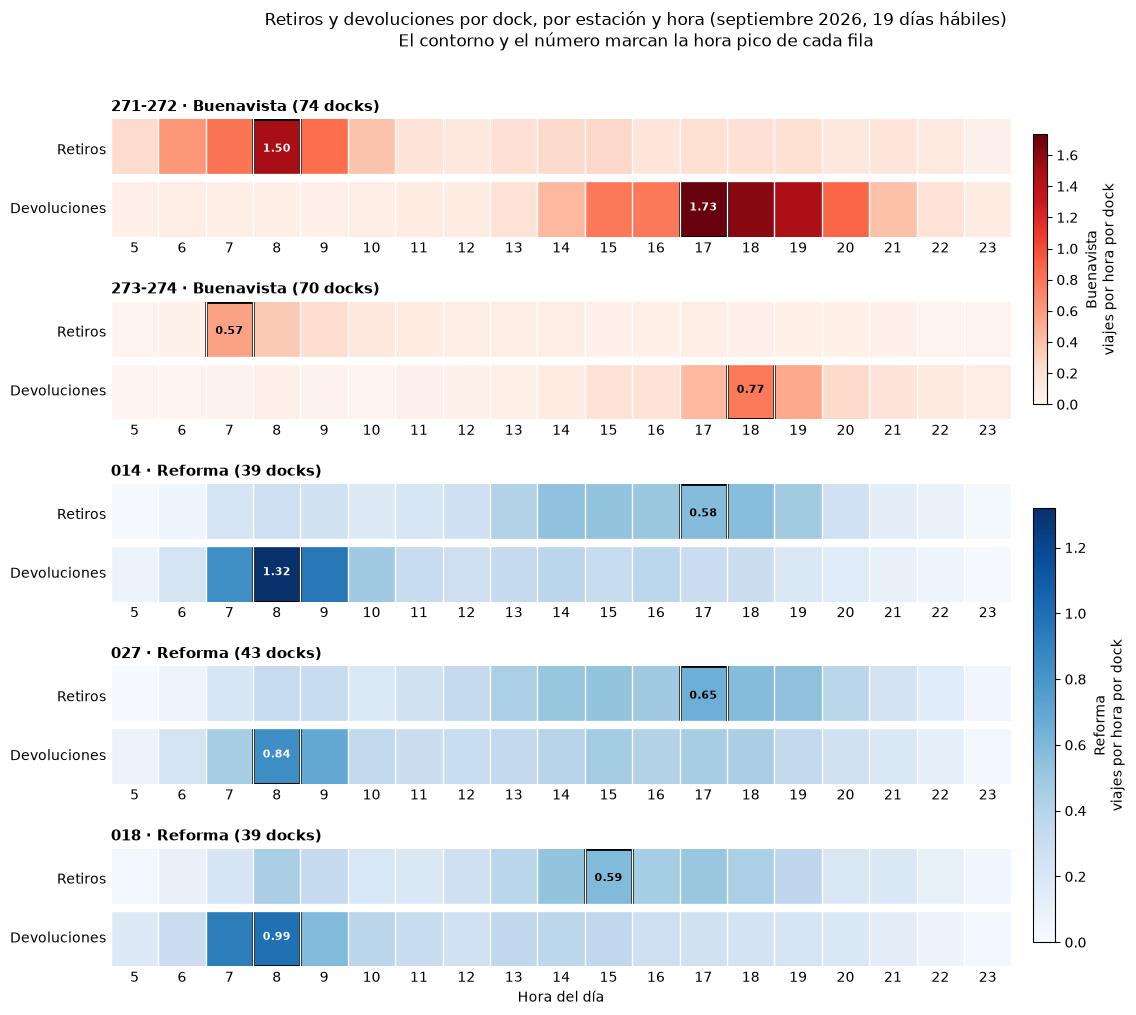

In [24]:
from matplotlib.patches import Rectangle

# Viajes por hora (promedio por día hábil) divididos entre los docks de cada estación
ret_mat = media_hora["retiros"].unstack().reindex(ESTACIONES).div(DOCKS, axis=0)
dev_mat = media_hora["devoluciones"].unstack().reindex(ESTACIONES).div(DOCKS, axis=0)

# Una escala de color por grupo (rojos para Buenavista, azules para Reforma)
CMAPS = {"Buenavista": "Reds", "Reforma": "Blues"}
vmax_grupo = {g: max(ret_mat.loc[[e for e in ESTACIONES if SUBRED[e] == g]].values.max(),
                     dev_mat.loc[[e for e in ESTACIONES if SUBRED[e] == g]].values.max())
              for g in CMAPS}

fig, axes = plt.subplots(len(ESTACIONES), 1, figsize=(14, 11), sharex=True,
                         gridspec_kw={"hspace": 0.55})
imagenes = {}
for ax, est in zip(axes, ESTACIONES):
    grupo = SUBRED[est]
    mat = np.vstack([ret_mat.loc[est].values, dev_mat.loc[est].values])     # fila 0 retiros, fila 1 devoluciones
    imagenes[grupo] = ax.imshow(mat, cmap=CMAPS[grupo], vmin=0, vmax=vmax_grupo[grupo], aspect="auto")

    # Hora pico de cada fila: contorno y valor
    for r in range(2):
        c = mat[r].argmax()
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec="black", lw=2))
        ax.text(c, r, f"{mat[r, c]:.2f}", ha="center", va="center", fontsize=8, weight="bold",
                color="white" if mat[r, c] > 0.6 * vmax_grupo[grupo] else "black")

    # Líneas blancas entre horas y una gruesa entre retiros y devoluciones
    ax.set_xticks(np.arange(-0.5, len(HORAS)), minor=True)
    ax.grid(which="minor", axis="x", color="white", lw=1)
    ax.axhline(0.5, color="white", lw=6)

    ax.set_yticks([0, 1], ["Retiros", "Devoluciones"])
    ax.set_xticks(range(len(HORAS)), HORAS)
    ax.tick_params(which="both", length=0, labelbottom=True)
    ax.spines[:].set_visible(False)
    ax.set_title(f"{est} · {grupo} ({DOCKS[est]} docks)", loc="left", fontsize=11, weight="bold")

axes[-1].set_xlabel("Hora del día")
for grupo, im in imagenes.items():
    ejes = [ax for ax, e in zip(axes, ESTACIONES) if SUBRED[e] == grupo]
    fig.colorbar(im, ax=ejes, shrink=0.9, pad=0.02, label=f"{grupo}\nviajes por hora por dock")
fig.suptitle(f"Retiros y devoluciones por dock, por estación y hora (septiembre 2026, {N_DIAS} días hábiles)\n"
             "El contorno y el número marcan la hora pico de cada fila", fontsize=12)

plt.savefig(DIR_FIG / "mapa_calor_estacion_hora.png", dpi=200, bbox_inches="tight")
plt.show()

**Qué se ve**

- Confirma los picos del paso 1 y agrega una cosa: en su hora pico, la **271-272** entrega 1.50 bicis por dock (8 h) y recibe 1.73 (17 h), y la **014** recibe 1.32 (8 h). Es decir, en una sola hora mueven más bicis de las que les caben. Sin camión se vaciarían o saturarían aunque empezaran en el mejor nivel posible; el paso 3 lo mide día por día.
- La **273-274** es la menos intensa por dock (0.57 y 0.77), aunque sea de las grandes.

*En pocas palabras: en hora pico, algunas estaciones mueven en una hora más bicis de las que caben en ellas.*

## 3. Desbalance sistemático

El **flujo neto acumulado** suma, desde las 5:00, las bicis que gana o pierde cada estación por los viajes. La curva muestra el promedio de los días hábiles y la banda el 80% central de los días.

Para cada estación y día, si el **rango** del acumulado (máximo − mínimo) es mayor que los docks, ningún inventario inicial permite pasar el día sin vaciarse o llenarse: la estación necesita camión. Es "sistemático" si pasa en la mayoría de los días.

,grupo,docks,rango_mediano,rango_entre_docks,dias_rango_mayor_docks,hora_mas_vacia,hora_mas_llena
271-272,Buenavista,74,497.0,6.7,19/19,14:00,23:59
273-274,Buenavista,70,168.0,2.4,19/19,14:00,23:59
014,Reforma,39,120.0,3.1,19/19,05:00,13:00
027,Reforma,43,78.0,1.8,18/19,05:00,12:00
018,Reforma,39,86.0,2.2,19/19,05:00,12:00


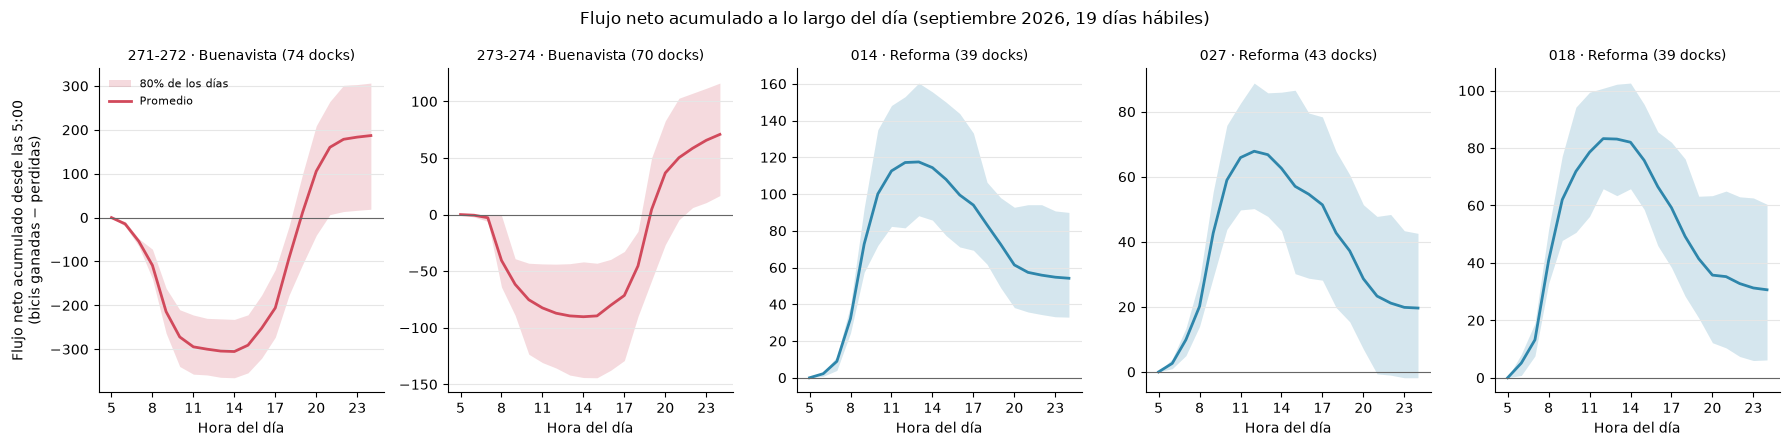

In [25]:
# --- Flujo neto acumulado por hora, desde las 5:00, para cada estación y día (para la curva)
flujo = conteos["devoluciones"] - conteos["retiros"]
acum = flujo.groupby(["estacion", "fecha"]).cumsum()                       # valor al cierre de cada hora
curva = acum.groupby(["estacion", "hora"]).agg(
    media="mean", p10=lambda s: s.quantile(0.10), p90=lambda s: s.quantile(0.90))

# --- Rango del acumulado por viaje: cada retiro resta 1 y cada devolución suma 1, en orden de tiempo
eventos = pd.concat([
    pd.DataFrame({"estacion": ret["estacion"], "fecha": ret["fecha"], "t": df.loc[m_ret, "retiro"], "cambio": -1}),
    pd.DataFrame({"estacion": dev["estacion"], "fecha": dev["fecha"], "t": df.loc[m_dev, "arribo"], "cambio": 1}),
]).sort_values(["estacion", "fecha", "t"])
eventos["acumulado"] = eventos.groupby(["estacion", "fecha"])["cambio"].cumsum()

por_dia = eventos.groupby(["estacion", "fecha"])["acumulado"].agg(["min", "max"])
por_dia = por_dia.reindex(pd.MultiIndex.from_product([ESTACIONES, DIAS], names=["estacion", "fecha"]), fill_value=0)
por_dia["rango"] = por_dia["max"].clip(lower=0) - por_dia["min"].clip(upper=0)   # el día arranca en 0
por_dia["excede"] = por_dia["rango"] > por_dia.index.get_level_values("estacion").map(DOCKS)

# --- Hora en que el acumulado promedio llega a su mínimo y a su máximo (5:00 = inicio, valor 0)
def hora_extremo(est, fn):
    serie = pd.concat([pd.Series({5: 0.0}), curva.loc[est, "media"].set_axis([h + 1 for h in HORAS])])
    h = getattr(serie, fn)()
    return f"{h:02d}:00" if h < 24 else "23:59"

desbalance = pd.DataFrame({
    "grupo": pd.Series(SUBRED),
    "docks": DOCKS,
    "rango_mediano": por_dia.groupby("estacion")["rango"].median(),
    "dias_rango_mayor_docks": por_dia.groupby("estacion")["excede"].sum().astype(int).astype(str) + f"/{N_DIAS}",
    "hora_mas_vacia": [hora_extremo(e, "idxmin") for e in ESTACIONES],
    "hora_mas_llena": [hora_extremo(e, "idxmax") for e in ESTACIONES],
}, index=ESTACIONES)
desbalance.insert(3, "rango_entre_docks", desbalance["rango_mediano"] / desbalance["docks"])
display(desbalance.round(1))

# --- Figura: flujo neto acumulado promedio con la banda del 80% central de los días
fig, axes = plt.subplots(1, len(ESTACIONES), figsize=(18, 4.5))
x = [5] + [h + 1 for h in HORAS]                      # 5:00 = inicio del día, luego cierre de cada hora
for ax, est in zip(axes, ESTACIONES):
    color = COLORES[SUBRED[est]]
    c = curva.loc[est]
    ax.fill_between(x, [0] + list(c["p10"]), [0] + list(c["p90"]), color=color, alpha=0.2, lw=0,
                    label="80% de los días")
    ax.plot(x, [0] + list(c["media"]), color=color, lw=2, label="Promedio")
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set_title(f"{est} · {SUBRED[est]} ({DOCKS[est]} docks)", fontsize=10)
    ax.set_xticks(range(5, 25, 3))
    ax.set_xlabel("Hora del día")
    ax.grid(axis="y", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Flujo neto acumulado desde las 5:00\n(bicis ganadas − perdidas)")
axes[0].legend(loc="upper left", fontsize=8, frameon=False)
fig.suptitle(f"Flujo neto acumulado a lo largo del día (septiembre 2026, {N_DIAS} días hábiles)", fontsize=12)
fig.tight_layout()
plt.savefig(DIR_FIG / "flujo_neto_acumulado.png", dpi=200, bbox_inches="tight")
plt.show()

**Qué se ve**

- **Las 5 estaciones están desbalanceadas todos los días.** En 94 de 95 estación-día el rango supera los docks: ninguna aguanta un día normal sin camión.
- **Buenavista se vacía en la mañana y se llena en la tarde; Reforma, al revés.** La 271-272 pierde unas 305 bicis antes de las 14:00 (4 veces sus docks) y la 014 acumula unas 117 al mediodía (3 veces).
- **No es efecto del promedio:** la banda del 80% de los días sigue el mismo patrón.
- El rango va de 1.8× los docks (027) a 6.7× (271-272), y es un mínimo: la demanda que no encontró bici o lugar no aparece en los datos.

*En pocas palabras: ninguna estación funciona un día normal sin que el camión mueva bicis.*

## 4. Política actual: movimientos del camión

Los datos no registran al camión, pero se puede reconstruir siguiendo cada bici: si **llega a una estación** y su **siguiente viaje sale de otra**, alguien la movió entre tanto. Si la bici estuvo quieta hasta 24 h se toma como rebalanceo; más tiempo suele ser mantenimiento.

Se usan los 12 meses (solo las columnas de bici, estaciones y horas) para no cortar la historia de una bici al cambio de mes, y se cuentan los movimientos de los días hábiles de septiembre que tocan la subred. Comparar lo que mueve el camión con el flujo neto de los usuarios (paso 1) dice si la reconstrucción cuadra.

*Es una reconstrucción, no un registro: el día del movimiento se aproxima con el del siguiente retiro de la bici.*

In [26]:
# Solo las columnas necesarias para seguir cada bici; se usan los 12 meses para no cortar
# las cadenas de una bici al cambio de mes (su último viaje de agosto y el primero de septiembre)
COLS_CAMION = ["Bici", COL_RET, COL_ARR, "retiro", "arribo"]
b = pd.read_parquet(Path("data/clean/trips_12m.parquet"), columns=COLS_CAMION)
b = b.sort_values(["Bici", "retiro"]).reset_index(drop=True)

# Para cada viaje, el siguiente viaje de la misma bici
sig = b.groupby("Bici", observed=True)[[COL_RET, "retiro"]].shift(-1)
llega = b[COL_ARR].astype(str)                     # donde quedó la bici
sale = sig[COL_RET].astype(str)                    # de donde salió en su siguiente viaje
horas_quieta = (sig["retiro"] - b["arribo"]).dt.total_seconds() / 3600

# Movimiento = la bici reaparece en otra estación sin un viaje de por medio.
# Hasta 24 h se toma como rebalanceo; más tiempo suele ser mantenimiento u otra cosa.
es_mov = sig["retiro"].notna() & (llega != sale) & horas_quieta.between(0, 24)
mov = pd.DataFrame({"desde": llega[es_mov], "hacia": sale[es_mov],
                    "fecha": sig.loc[es_mov, "retiro"].dt.normalize()})   # día aproximado: el del siguiente retiro
del b, sig

# Septiembre, días hábiles, movimientos que tocan la subred
mov = mov[mov["fecha"].isin(DIAS) & (mov["desde"].isin(SUBRED) | mov["hacia"].isin(SUBRED))]

camion = pd.DataFrame({
    "grupo": pd.Series(SUBRED),
    "camion_saca_dia": mov.groupby("desde").size().reindex(ESTACIONES, fill_value=0) / N_DIAS,
    "camion_deja_dia": mov.groupby("hacia").size().reindex(ESTACIONES, fill_value=0) / N_DIAS,
}, index=ESTACIONES)
camion["camion_neto_dia"] = camion["camion_deja_dia"] - camion["camion_saca_dia"]
camion["flujo_neto_usuarios_dia"] = resumen["flujo_neto_dia"]
camion["balance_final_dia"] = camion["flujo_neto_usuarios_dia"] + camion["camion_neto_dia"]
display(camion.round(1))

# ¿El camión mueve bicis entre estaciones de la subred o hacia fuera?
grupo_de = lambda s: s.map(SUBRED).fillna("Fuera")
entre_grupos = pd.crosstab(grupo_de(mov["desde"]), grupo_de(mov["hacia"])) / N_DIAS
entre_grupos.index.name, entre_grupos.columns.name = "desde", "hacia"
display(entre_grupos.round(1))

,grupo,camion_saca_dia,camion_deja_dia,camion_neto_dia,flujo_neto_usuarios_dia,balance_final_dia
271-272,Buenavista,420.8,251.3,-169.5,186.9,17.5
273-274,Buenavista,113.3,49.3,-64.1,70.8,6.8
014,Reforma,95.4,41.1,-54.4,54.2,-0.2
027,Reforma,51.7,31.8,-19.9,19.6,-0.3
018,Reforma,59.7,31.5,-28.2,30.6,2.5


hacia,Buenavista,Fuera,Reforma
desde,,,
Buenavista,0.3,453.6,80.2
Fuera,195.1,0.0,23.5
Reforma,105.2,101.1,0.6


**Qué se ve**

- **El camión compensa a los usuarios.** En las 5 estaciones el camión saca más bicis de las que deja, y ese neto negativo cancela casi exacto el flujo neto positivo de los usuarios: el balance final queda cerca de 0 (entre −0.3 y +17 bicis por día). Esto confirma lo que dedujimos en el paso 3: las estaciones solo funcionan porque el camión saca el excedente todos los días.
- **Buenavista manda muchas bicis fuera de la red.** El camión saca unas 454 bicis por día de Buenavista hacia otras estaciones y le trae unas 195 de fuera. Esas bicis podrían aprovecharse dentro de la red.
- **Reforma ya manda bicis a Buenavista, pero no alcanzan.** Son unas 105 por día, frente a las ~395 que Buenavista pierde en la mañana. Como sus horarios son complementarios (Reforma junta unas 270 bicis para el mediodía mientras Buenavista se vacía), hay margen para mover más bicis de Reforma a Buenavista en la mañana.
- **En la tarde la red no se compensa sola.** Buenavista gana unas 650 bicis y Reforma solo pierde unas 160, así que la mayor parte del excedente de la tarde tiene que salir de la red.

Por eso tiene sentido redistribuir entre estaciones cercanas como estas, pero el modelo necesita también un depósito o "exterior" para el excedente.

*En pocas palabras: hoy el camión saca muchas bicis de la red; parte de ellas podría usarse para rellenar Buenavista en la mañana con las que sobran en Reforma.*

## 5. Conclusiones de la Etapa 1

**1. Subred y periodo seleccionados y justificados** (`data_cleaning.ipynb`)
- **Subred:** 5 estaciones; 3 de Reforma (014, 027, 018; 39 a 43 docks) y 2 de Buenavista (271-272 y 273-274; 74 y 70 docks). Se eligieron porque se complementan: Buenavista se vacía en la mañana cuando Reforma se llena, y en la tarde al revés (pasos 1 y 3). Se empieza con 5 por indicación del profesor.
- **Periodo:** septiembre 2026, el mes más reciente publicado, con 19 días hábiles. Se excluyen el festivo del 16 y el 14–15 por el cierre en Buenavista. Es un mes representativo: 1,348 retiros por día hábil en la subred, dentro del rango de los 12 meses (1,110 a 1,452).

**2. Decisiones de limpieza documentadas** (`data_cleaning.ipynb`)
- Se aplicaron 8 reglas a los 12 meses y se eliminó el 0.235% de los viajes (43,859 de 18.68 millones). La que más quitó es *misma estación y menos de 3 min* (31,218). La limpieza no cambia la forma de los datos.

**3. Estadísticas descriptivas por estación y hora** (pasos 1 y 2)
- **Buenavista** entrega bicis en la mañana y las recibe en la tarde: la 271-272 tiene 111 retiros a las 8 h y 128 devoluciones a las 17 h. **Reforma** es el espejo: recibe a las 8 h (hasta 51 por hora en la 014) y entrega por la tarde (15 a 17 h).
- Por dock, la 271-272 y la 014 son las más intensas: en su hora pico mueven más bicis de las que les caben (1.50, 1.73 y 1.32 por dock).
- La variación entre días es alta en hora pico (271-272 a las 8 h: 111 ± 42), sobre todo en Buenavista.

**4. Estaciones sistemáticamente desbalanceadas** (pasos 3 y 4)
- **Las 5 lo están.** En 94 de los 95 estación-día el rango del flujo neto supera los docks, así que ninguna puede pasar un día normal sin camión. El rango va de 1.8 veces los docks (027) a 6.7 veces (271-272).
- **Sentido y hora:** Buenavista se vacía hasta las 14:00 y se llena hasta el cierre; Reforma se llena hasta el mediodía.
- Además, las 5 terminan el día con más bicis de las que empezaron (de +20 a +187 por día). El camión compensa ese excedente casi exacto: la reconstrucción de sus movimientos deja el balance final cerca de 0.

**5. Implicaciones para la Etapa 2**
- **Parámetros por hora:** λ (devoluciones) y μ (retiros) cambian mucho durante el día, así que el modelo M/M/1/N debe usar tasas por hora y seguir el día de forma transitoria (cada hora arranca de cómo terminó la anterior), no en estado estable.
- **Depósito o "exterior":** la red gana unas 360 bicis por día y en la tarde no se compensa sola, así que no basta con mover bicis entre las 5 estaciones.
- **Horas críticas para el camión:** rellenar Buenavista de 6 a 10 h y vaciarla de 15 a 20 h; vaciar Reforma de 8 a 12 h. En la mañana, las bicis que sobran en Reforma pueden cubrir parte del faltante de Buenavista (hoy el camión mueve unas 105 por día en ese sentido).
- **Política actual como línea base:** los movimientos reconstruidos del camión son la referencia contra la que se compararán las propuestas.
- **Demanda censurada:** los datos solo registran viajes completados y ya incluyen el efecto del camión; cuando una estación estuvo vacía o llena, la demanda real no aparece. Se trabajará en la siguiente etapa.

**Limitaciones:** 19 días hábiles de un solo mes; capacidad tomada del feed actual (no de septiembre); movimientos del camión reconstruidos, no registrados.